# Is interleaving really 50x faster than an A/B test? Rebuilding Airbnb's ranking experiments on MovieLens

Independent rebuild of Zhang, Deng, Du, Gao, He, Katariya, *Harnessing the Power of Interleaving and Counterfactual
Evaluation for Airbnb Search Ranking* (KDD 2025, [arXiv 2508.00751](https://arxiv.org/abs/2508.00751)).
Hypotheses and pass/fail rules were committed before any simulation (`PREREGISTRATION.md`).

**Assumptions** (numbered, used throughout)
1. Tastes are real: truncated SVD (k = 16) of the liked (rating >= 4) matrix of MovieLens, 2,000 most-rated movies. Bookings are simulated.
2. A search draws 50 candidate movies at random; a ranker orders them; the top 10 are shown.
3. Booking model: attention a_r = 1/log2(r + 1). The user books the item at rank r with probability a_r exp(u_r) / (exp(c) + sum_r a_r exp(u_r)). At most one booking per search.
4. Appeal u = 3 x taste similarity + 0.5 x standardized log popularity. c is set so about 3% of searches end in a booking under a typical ranker.
5. Each user searches twice (Airbnb users travel rarely). The unit of analysis is the user for both A/B and interleaving.
6. Every expectation (true A/B effect, expected interleaving preference) is computed exactly from the choice model over the same 100,000 simulated searches, so ranker differences are not blurred by sampling noise.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, os, time
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

os.makedirs("figures", exist_ok=True)
PARQUET_URL = "https://huggingface.co/datasets/ashraq/movielens_ratings/resolve/main/data/train-00000-of-00001-8c8c7645a52d95e5.parquet"
df = pd.read_parquet("ratings.parquet" if os.path.exists("ratings.parquet") else PARQUET_URL).rename(columns={"movie_id": "movieId", "user_id": "userId"})
N_ITEMS, K_TRUE = 2000, 16
top = df.groupby("movieId").size().sort_values(ascending=False).index[:N_ITEMS]
d = df[df.movieId.isin(top)]
uc = d.groupby("userId").size(); d = d[d.userId.isin(uc[uc >= 10].index)]
uidx = {u: i for i, u in enumerate(d.userId.unique())}; tidx = {t: i for i, t in enumerate(top)}
rows, cols = d.userId.map(uidx).values, d.movieId.map(tidx).values
LIKED = csr_matrix(((d.rating >= 4).astype(float).values, (rows, cols)), shape=(len(uidx), N_ITEMS))

def factors(M, k):
    u_, s_, vt_ = svds(M, k=k, random_state=0)
    U = u_ * np.sqrt(s_); V = vt_.T * np.sqrt(s_)
    U -= U.mean(0); V -= V.mean(0)
    return U / (np.linalg.norm(U, axis=1, keepdims=True) + 1e-9), V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-9)

Un, Vn = factors(LIKED, K_TRUE)
cnt = d.groupby("movieId").size().reindex(top).values
POP = (np.log(cnt) - np.log(cnt).mean()) / np.log(cnt).std()
meta = df.drop_duplicates("movieId").set_index("movieId").reindex(top)
GENRES = meta.genres.fillna("").str.split("|").apply(lambda g: [x for x in g if x])
ALLG = sorted({g for gs in GENRES for g in gs})
GMAT = np.array([[g in gs for g in ALLG] for gs in GENRES], float)          # items x genres
print(f"{len(uidx):,} users, {N_ITEMS} movies, {len(ALLG)} genres")

18,294 users, 2000 movies, 19 genres


## The search world, rankers and the two experiment designs

In [2]:
N_CAND, N_SHOW, N_SEARCH = 50, 10, 100_000
ATT = 1 / np.log2(np.arange(2, N_SHOW + 2))
rng = np.random.default_rng(7)
S_USER = rng.integers(0, len(uidx), N_SEARCH // 2).repeat(2)            # each user searches twice
S_CAND = np.array([rng.choice(N_ITEMS, N_CAND, replace=False) for _ in range(N_SEARCH)])
TASTE = np.einsum("sk,sck->sc", Un[S_USER], Vn[S_CAND])
APPEAL = 3.0 * TASTE + 0.5 * POP[S_CAND]

# rankers: each returns a score per candidate (higher = shown first)
mf = {k: factors(LIKED, k) for k in [2, 4, 8, 32]}
def ranker_scores(name, rs):
    if name == "oracle": return APPEAL
    if name.startswith("noise"): return APPEAL + rs.normal(0, float(name[5:]), APPEAL.shape)
    if name.startswith("mf"):
        U, V = mf[int(name[2:])]; return np.einsum("sk,sck->sc", U[S_USER], V[S_CAND]) + 0.15 * POP[S_CAND]
    if name == "popularity": return POP[S_CAND] + 1e-6 * rs.random(APPEAL.shape)
    if name == "random": return rs.random(APPEAL.shape)
RANKERS = ["oracle", "noise0.5", "noise1", "noise1.5", "noise2", "noise3", "mf2", "mf4", "mf8", "mf32", "popularity", "random"]
ORDER = {r: np.argsort(-ranker_scores(r, np.random.default_rng(100 + i)), axis=1) for i, r in enumerate(RANKERS)}   # positions into S_CAND

def book_probs(app_list, c):
    """Booking probability per shown slot. app_list: S x 10 appeal of the shown items."""
    w = ATT * np.exp(app_list)
    return w / (np.exp(c) + w.sum(1, keepdims=True))

def shown_appeal(order, appeal=None):
    A = APPEAL if appeal is None else appeal
    return np.take_along_axis(A, order[:, :N_SHOW], axis=1)

# calibrate c: about 3% booking rate under the median-quality ranker (noise1.5)
from scipy.optimize import brentq
C_OUT = brentq(lambda c: book_probs(shown_appeal(ORDER["noise1.5"]), c).sum(1).mean() - 0.03, -5, 20)
conv = {r: book_probs(shown_appeal(ORDER[r]), C_OUT).sum(1) for r in RANKERS}
print("outside option c =", round(C_OUT, 2))
print(pd.Series({r: v.mean() for r, v in conv.items()}).round(4).to_string())

outside option c = 6.13
oracle        0.0461
noise0.5      0.0412
noise1        0.0347
noise1.5      0.0300
noise2        0.0269
noise3        0.0234
mf2           0.0333
mf4           0.0376
mf8           0.0423
mf32          0.0424
popularity    0.0324
random        0.0167


**Team draft with competitive pairs (Airbnb's Algorithm 1)**, vectorized over searches.
One coin flip per search decides which team goes first in every pair. Each turn drafts the next item not yet shown from each ranker.
Different items form a competitive pair; the same item is added once with no team. The list is cut at 10.

In [3]:
def team_draft(oc, ot, rs):
    S = oc.shape[0]
    merged = np.full((S, N_SHOW), -1); team = np.zeros((S, N_SHOW), int)   # +1 = treatment, -1 = control, 0 = none
    used = np.zeros((S, N_CAND), bool)
    pc = np.zeros(S, int); pt = np.zeros(S, int); fill = np.zeros(S, int)
    c_first = rs.random(S) < 0.5
    ar = np.arange(S)
    while (fill < N_SHOW).any():
        act = fill < N_SHOW
        for p, o in ((pc, oc), (pt, ot)):
            while True:
                need = act & used[ar, o[ar, np.minimum(p, N_CAND - 1)]] & (p < N_CAND - 1)
                if not need.any(): break
                p[need] += 1
        a, b = oc[ar, pc], ot[ar, pt]
        same = act & (a == b)
        diff = act & (a != b)
        # same item: add once, no team
        merged[same, fill[same]] = a[same]; used[same, a[same]] = True; fill[same] += 1
        # competitive pair: order by coin flip, second item only if room
        first = np.where(c_first, a, b); second = np.where(c_first, b, a)
        tf = np.where(c_first, -1, 1); ts = -tf
        merged[diff, fill[diff]] = first[diff]; team[diff, fill[diff]] = tf[diff]; used[diff, first[diff]] = True; fill[diff] += 1
        room = diff & (fill < N_SHOW)
        merged[room, fill[room]] = second[room]; team[room, fill[room]] = ts[room]; used[room, second[room]] = True; fill[room] += 1
    return merged, team

def pair_stats(rc, rt, appeal=None, seed=0, c=None):
    """Exact per-search probabilities for A/B (each ranker alone) and interleaving (merged list)."""
    A = APPEAL if appeal is None else appeal
    c = C_OUT if c is None else c
    pC = book_probs(np.take_along_axis(A, ORDER[rc][:, :N_SHOW], 1), c).sum(1)
    pT = book_probs(np.take_along_axis(A, ORDER[rt][:, :N_SHOW], 1), c).sum(1)
    merged, team = team_draft(ORDER[rc], ORDER[rt], np.random.default_rng(seed))
    pm = book_probs(np.take_along_axis(A, merged, 1), c)
    winT = (pm * (team == 1)).sum(1); winC = (pm * (team == -1)).sum(1)
    return pC, pT, winT, winC

def ab_user_moments(p):
    """Bookings per user over two searches: mean and variance (law of total variance, Bernoulli searches)."""
    p2 = p.reshape(-1, 2)
    m = p2.sum(1); v_within = (p2 * (1 - p2)).sum(1)
    return m.mean(), v_within.mean() + m.var()

def il_user_dist(winT, winC):
    """Exact distribution of the user's preference sign over two searches."""
    t, c = winT.reshape(-1, 2), winC.reshape(-1, 2)
    o = 1 - t - c
    # outcomes per search: T, C, other. User prefers T if more T wins than C wins.
    pos = t[:, 0] * (t[:, 1] + o[:, 1]) + o[:, 0] * t[:, 1]
    neg = c[:, 0] * (c[:, 1] + o[:, 1]) + o[:, 0] * c[:, 1]
    return pos.mean(), neg.mean()

Z2 = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) ** 2
def sample_sizes(pC, pT, winT, winC):
    mC, vC = ab_user_moments(pC); mT, vT = ab_user_moments(pT)
    delta = mT - mC
    n_ab = 2 * Z2 * (vC + vT) / delta**2 if delta != 0 else np.inf      # total users, two arms
    pp, pn = il_user_dist(winT, winC)
    mean_s, var_s = pp - pn, pp + pn - (pp - pn) ** 2
    n_il = Z2 * var_s / mean_s**2 if mean_s != 0 else np.inf
    return dict(ab_effect=delta / 2, ab_rel=delta / mC, il_pref=mean_s, n_ab=n_ab, n_il=n_il, speedup=n_ab / n_il)

## H2, H3, H4: speedup and agreement across all ranker pairs (pre-registered set)

In [4]:
from itertools import combinations
rows = []
for rc, rt in combinations(RANKERS, 2):
    r = sample_sizes(*pair_stats(rc, rt))
    ov = np.mean([len(set(a) & set(b)) / N_SHOW for a, b in zip(ORDER[rc][:20000, :N_SHOW], ORDER[rt][:20000, :N_SHOW])])
    rows.append(dict(control=rc, treatment=rt, top10_overlap=ov, **r))
P = pd.DataFrame(rows)
P["agree"] = np.sign(P.ab_effect) == np.sign(P.il_pref)
finite = P[np.isfinite(P.speedup)]
RES = {}
RES["H2"] = dict(n_pairs=len(P), median_speedup=float(finite.speedup.median()), q25=float(finite.speedup.quantile(0.25)),
                 q75=float(finite.speedup.quantile(0.75)), pass_=bool(finite.speedup.median() >= 10))
RES["H3"] = dict(sign_agreement=float(P.agree.mean()), corr=float(np.corrcoef(P.ab_effect, P.il_pref)[0, 1]), pass_=bool(P.agree.mean() >= 0.80))
RES["H4"] = dict(max_speedup=float(finite.speedup.max()), min_speedup=float(finite.speedup.min()),
                 ratio=float(finite.speedup.max() / finite.speedup.min()), pass_=bool(finite.speedup.max() / finite.speedup.min() > 5))
print(P.sort_values("speedup").round(4).to_string(index=False))
for k in ["H2", "H3", "H4"]: print(k, RES[k])

   control  treatment  top10_overlap  ab_effect  ab_rel  il_pref         n_ab         n_il  speedup  agree
       mf8       mf32         0.6145     0.0001  0.0032   0.0000 3.406611e+07 3.572942e+08   0.0953   True
    noise3     random         0.1997    -0.0067 -0.2856  -0.0089 6.930484e+03 3.979081e+03   1.7417   True
       mf2     random         0.1996    -0.0166 -0.4987  -0.0229 1.390819e+03 7.762192e+02   1.7918   True
    noise2     random         0.1985    -0.0102 -0.3788  -0.0139 3.234888e+03 1.789914e+03   1.8073   True
  noise1.5     random         0.2000    -0.0133 -0.4432  -0.0186 2.029539e+03 1.092333e+03   1.8580   True
popularity     random         0.2002    -0.0157 -0.4844  -0.0222 1.527583e+03 8.183341e+02   1.8667   True
    noise1     random         0.1997    -0.0180 -0.5192  -0.0258 1.210382e+03 6.367234e+02   1.9010   True
       mf4     random         0.1994    -0.0209 -0.5562  -0.0301 9.484314e+02 4.982222e+02   1.9036   True
      mf32     random         0.1989 

## Exploratory (not pre-registered): production-style iterations
Real ranking work compares a model with a slightly better version of itself. Here the control is the 8-factor MF ranker
and the treatment blends in a little of the true appeal (weight w). Small w means a small change.

In [5]:
def zs(x): return (x - x.mean(1, keepdims=True)) / (x.std(1, keepdims=True) + 1e-9)
U8, V8 = mf[8]
MF8 = zs(np.einsum("sk,sck->sc", U8[S_USER], V8[S_CAND]) + 0.15 * POP[S_CAND])
ZA = zs(APPEAL)
ORDER["base"] = np.argsort(-MF8, axis=1)
rows_it = []
for wgt in [0.02, 0.05, 0.1, 0.2, 0.4, 0.7]:
    name = f"iter{wgt}"
    ORDER[name] = np.argsort(-((1 - wgt) * MF8 + wgt * ZA), axis=1)
    r = sample_sizes(*pair_stats("base", name))
    overlap = np.mean([len(set(a) & set(b)) / N_SHOW for a, b in zip(ORDER["base"][:20000, :N_SHOW], ORDER[name][:20000, :N_SHOW])])
    rows_it.append(dict(w=wgt, top10_overlap=overlap, **r))
IT = pd.DataFrame(rows_it); print(IT.round(4).to_string(index=False))
RES["iterations"] = IT.to_dict(orient="records")

   w  top10_overlap  ab_effect  ab_rel  il_pref         n_ab       n_il   speedup
0.02         0.9929     0.0001  0.0034   0.0011 3.058301e+07 23073.6662 1325.4508
0.05         0.9822     0.0004  0.0084   0.0025 5.081277e+06 10787.8935  471.0166
0.10         0.9663     0.0007  0.0165   0.0042 1.323950e+06  6515.3104  203.2059
0.20         0.9363     0.0013  0.0318   0.0065 3.586523e+05  4361.4343   82.2327
0.40         0.8790     0.0024  0.0573   0.0089 1.119657e+05  3466.0175   32.3039
0.70         0.7964     0.0035  0.0820   0.0099 5.529568e+04  3606.4997   15.3322


## H1: is the credit scheme unbiased? Users who book by position only
2,000 simulated interleaving tests of 20,000 users each, on ranker pairs drawn at random. Users ignore content.

In [6]:
rs = np.random.default_rng(31)
K_POS = 0.03 / ATT.sum()
fp = 0; NT = 2000; n_users = 20_000
pairs_all = list(combinations(RANKERS, 2))
cache = {}
for t in range(NT):
    rc, rt = pairs_all[rs.integers(len(pairs_all))]
    if (rc, rt) not in cache:
        _, team = team_draft(ORDER[rc], ORDER[rt], np.random.default_rng(t))
        cache[(rc, rt)] = ((team == 1) * ATT * K_POS).sum(1), ((team == -1) * ATT * K_POS).sum(1)
    pT, pC = cache[(rc, rt)]
    users = rs.choice(N_SEARCH // 2, n_users)
    idx = (users[:, None] * 2 + np.arange(2)).ravel()
    u = rs.random(len(idx))
    wT = (u < pT[idx]).reshape(-1, 2).sum(1); wC = ((u >= pT[idx]) & (u < pT[idx] + pC[idx])).reshape(-1, 2).sum(1)
    nT, nC = (wT > wC).sum(), (wC > wT).sum()
    if nT + nC > 0 and stats.binomtest(int(nT), int(nT + nC), 0.5).pvalue < 0.05: fp += 1
lo, hi = stats.binomtest(fp, NT).proportion_ci(0.95)
RES["H1"] = dict(fpr=fp / NT, ci=[lo, hi], pass_=bool(0.035 <= fp / NT <= 0.065))
print("H1", RES["H1"])

H1 {'fpr': 0.0425, 'ci': [np.float64(0.034086074593150856), np.float64(0.05228591324237418)], 'pass_': True}


## H5: a diversity ranker when the user's intent is hidden
Each search now has a hidden genre intent, drawn from the genres the user liked. Movies in the intended genre get +2 appeal.
The control ranks by the appeal it can see (no intent). The diversity ranker re-ranks the same scores greedily, penalizing
genres already shown (strength lambda). Which ranker wins in an A/B test, and which wins in interleaving?

In [7]:
ug = np.asarray(LIKED @ GMAT) + 0.5
ug = ug / ug.sum(1, keepdims=True)
rs = np.random.default_rng(41)
cum = ug[S_USER].cumsum(1)
INTENT = (rs.random((N_SEARCH, 1)) > cum).sum(1)
INT_BONUS = 2.0
APPEAL_I = APPEAL + INT_BONUS * GMAT[S_CAND, INTENT[:, None]]
ORDER["relevance"] = np.argsort(-APPEAL, axis=1)
C_INT = brentq(lambda c: book_probs(shown_appeal(ORDER["relevance"], APPEAL_I), c).sum(1).mean() - 0.03, -5, 25)

def mmr_order(score, lam):
    S = score.shape[0]; z = zs(score)
    chosen = np.zeros((S, N_SHOW), int); taken = np.zeros_like(z, bool); gcount = np.zeros((S, len(ALLG)))
    G = GMAT[S_CAND]                                     # S x 50 x genres
    for k in range(N_SHOW):
        overlap = (G * gcount[:, None, :]).sum(2) / np.maximum(G.sum(2), 1)
        val = np.where(taken, -np.inf, z - lam * overlap)
        j = val.argmax(1); chosen[:, k] = j; taken[np.arange(S), j] = True
        gcount += G[np.arange(S), j]
    rest = np.argsort(np.where(taken, np.inf, -z), axis=1)[:, : N_CAND - N_SHOW]
    return np.hstack([chosen, rest])

rows5 = []
for lam in [0.1, 0.25, 0.5, 1.0, 2.0]:
    name = f"div{lam}"; ORDER[name] = mmr_order(APPEAL, lam)
    pC, pT, wT, wC = pair_stats("relevance", name, appeal=APPEAL_I, c=C_INT)
    r = sample_sizes(pC, pT, wT, wC)
    rows5.append(dict(lam=lam, ab_rel=r["ab_rel"], ab_effect=r["ab_effect"], il_pref=r["il_pref"], agree=bool(np.sign(r["ab_effect"]) == np.sign(r["il_pref"]))))
D5 = pd.DataFrame(rows5); print(D5.round(5).to_string(index=False))
RES["H5"] = dict(table=D5.to_dict(orient="records"), pass_=bool((~D5.agree).any()))
print("H5 (break found):", RES["H5"]["pass_"])

 lam   ab_rel  ab_effect  il_pref  agree
0.10 -0.00478   -0.00014 -0.00078   True
0.25 -0.01529   -0.00046 -0.00184   True
0.50 -0.03516   -0.00105 -0.00326   True
1.00 -0.07211   -0.00216 -0.00535   True
2.00 -0.12369   -0.00371 -0.00788   True
H5 (break found): False


## Exploratory (added after H5 failed, not pre-registered): a list-level effect
In the pre-registered world each item is judged on its own, so there is no real set-level effect. Here users also judge the
list as a whole: the more the top 10 is dominated by one genre, the more likely they leave without booking
(outside option c + phi x share of the most common primary genre, phi = 3). This is the situation Airbnb describes.

In [8]:
PRIM = np.array([ALLG.index(g[0]) if len(g) else 0 for g in GENRES])
PHI = 3.0
def list_c(items, c0):
    prim = PRIM[np.take_along_axis(S_CAND, items, 1)]
    share = np.array([np.bincount(r, minlength=len(ALLG)).max() for r in prim]) / N_SHOW
    return (c0 + PHI * share)[:, None]
C_L = brentq(lambda c: book_probs(shown_appeal(ORDER["relevance"]), list_c(ORDER["relevance"][:, :N_SHOW], c)).sum(1).mean() - 0.03, -5, 25)
rows6 = []
for lam in [0.1, 0.25, 0.5, 1.0, 2.0]:
    name = f"div{lam}"
    oc, ot = ORDER["relevance"][:, :N_SHOW], ORDER[name][:, :N_SHOW]
    pC = book_probs(np.take_along_axis(APPEAL, oc, 1), list_c(oc, C_L)).sum(1)
    pT = book_probs(np.take_along_axis(APPEAL, ot, 1), list_c(ot, C_L)).sum(1)
    merged, team = team_draft(ORDER["relevance"], ORDER[name], np.random.default_rng(5))
    pm = book_probs(np.take_along_axis(APPEAL, merged, 1), list_c(merged, C_L))
    r = sample_sizes(pC, pT, (pm * (team == 1)).sum(1), (pm * (team == -1)).sum(1))
    rows6.append(dict(lam=lam, ab_rel=r["ab_rel"], il_pref=r["il_pref"], agree=bool(np.sign(r["ab_effect"]) == np.sign(r["il_pref"]))))
D6 = pd.DataFrame(rows6); print(D6.round(5).to_string(index=False))
RES["list_level"] = D6.to_dict(orient="records")

 lam  ab_rel  il_pref  agree
0.10 0.07034 -0.00019  False
0.25 0.14289 -0.00074  False
0.50 0.22010 -0.00170  False
1.00 0.30366 -0.00334  False
2.00 0.35050 -0.00559  False


## Sensitivity: does the conclusion depend on my booking model?
The booking rate (Assumption 4) and the attention curve (Assumption 3) are my choices, not Airbnb's. Rerun the pre-registered
pairs and two production-style iterations under other settings.

In [9]:
ATT0, C0 = ATT.copy(), C_OUT
sens = []
for label, target, att in [("3%, 1/log2(r+1) (main)", 0.03, ATT0), ("1% booking rate", 0.01, ATT0), ("10% booking rate", 0.10, ATT0),
                           ("steeper attention 1/r", 0.03, 1 / np.arange(1, N_SHOW + 1))]:
    ATT = att
    C_OUT = brentq(lambda c: book_probs(shown_appeal(ORDER["noise1.5"]), c).sum(1).mean() - target, -10, 30)
    sp = [sample_sizes(*pair_stats(a, b))["speedup"] for a, b in combinations(RANKERS, 2)]
    it = {w: sample_sizes(*pair_stats("base", f"iter{w}"))["speedup"] for w in [0.1, 0.4]}
    sens.append(dict(setting=label, median_speedup_all_pairs=float(np.median([x for x in sp if np.isfinite(x)])),
                     speedup_iter_w0_1=float(it[0.1]), speedup_iter_w0_4=float(it[0.4])))
ATT, C_OUT = ATT0, C0
SENS = pd.DataFrame(sens); print(SENS.round(1).to_string(index=False))
RES["sensitivity"] = SENS.to_dict(orient="records")

               setting  median_speedup_all_pairs  speedup_iter_w0_1  speedup_iter_w0_4
3%, 1/log2(r+1) (main)                       3.0              203.2               32.3
       1% booking rate                       2.9              199.2               31.8
      10% booking rate                       3.3              217.3               34.1
 steeper attention 1/r                       2.3              113.3               20.6


## Figures

{'H1': True, 'H2': False, 'H3': True, 'H4': True, 'H5': False}


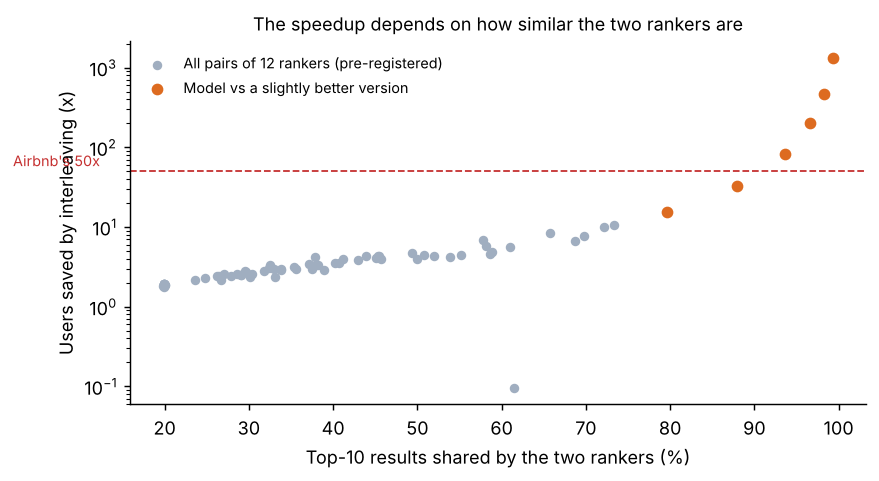

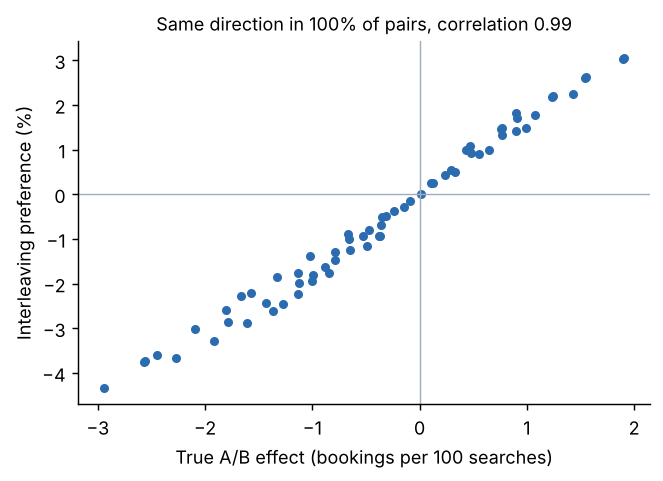

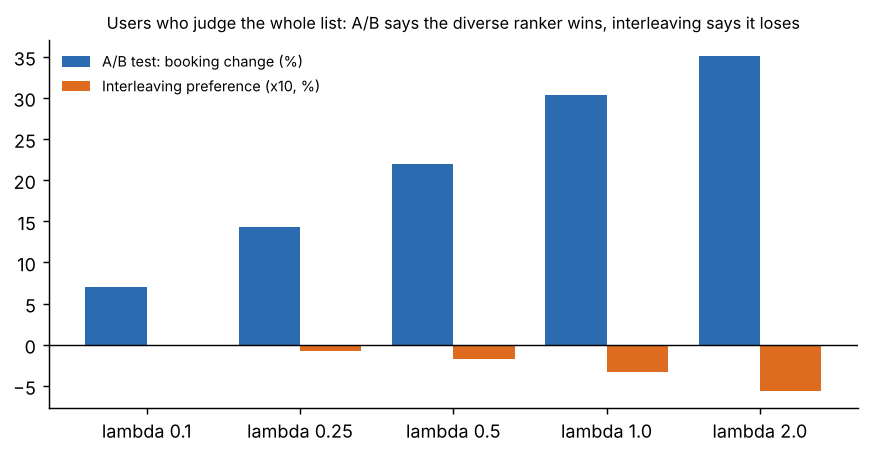

In [10]:
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY, RED = "#2b6cb0", "#dd6b20", "#a0aec0", "#c53030"

fig, ax = plt.subplots(figsize=(6.8, 3.8))
f = P[np.isfinite(P.speedup) & (P.speedup > 0)]
ax.scatter(f.top10_overlap * 100, f.speedup, s=18, color=GREY, label="All pairs of 12 rankers (pre-registered)")
ax.scatter(IT.top10_overlap * 100, IT.speedup, s=30, color=ORANGE, label="Model vs a slightly better version")
ax.set_yscale("log"); ax.axhline(50, color=RED, ls="--", lw=1); ax.text(2, 58, "Airbnb's 50x", color=RED, fontsize=8)
ax.set_xlabel("Top-10 results shared by the two rankers (%)"); ax.set_ylabel("Users saved by interleaving (x)")
ax.set_title("The speedup depends on how similar the two rankers are", fontsize=10); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig1_speedup_vs_overlap.png", dpi=200)

fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.scatter(P.ab_effect * 100, P.il_pref * 100, s=16, color=BLUE)
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ax.set_xlabel("True A/B effect (bookings per 100 searches)"); ax.set_ylabel("Interleaving preference (%)")
ax.set_title(f"Same direction in {RES['H3']['sign_agreement']*100:.0f}% of pairs, correlation {RES['H3']['corr']:.2f}", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig2_agreement.png", dpi=200)

fig, ax = plt.subplots(figsize=(6.8, 3.6))
x = np.arange(len(D6))
ax.bar(x - 0.2, D6.ab_rel * 100, 0.4, color=BLUE, label="A/B test: booking change (%)")
ax.bar(x + 0.2, D6.il_pref * 100 * 10, 0.4, color=ORANGE, label="Interleaving preference (x10, %)")
ax.axhline(0, color="black", lw=0.8); ax.set_xticks(x); ax.set_xticklabels([f"lambda {l}" for l in D6.lam])
ax.set_title("Users who judge the whole list: A/B says the diverse ranker wins, interleaving says it loses", fontsize=9)
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig("figures/fig3_list_level.png", dpi=200)

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
RES["pairs"] = P.to_dict(orient="records")
json.dump(clean(RES), open("figures/results.json", "w"), indent=1)
print({k: RES[k]["pass_"] for k in ["H1", "H2", "H3", "H4", "H5"]})

## Scorecard

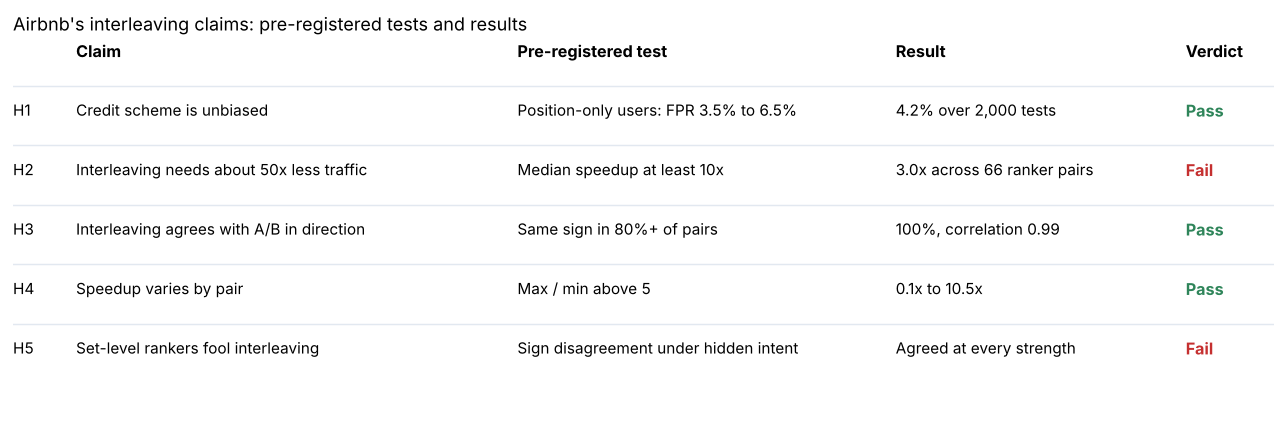

In [11]:
def scorecard(rows, title, path):
    """rows: (id, claim, test, result, verdict). Verdict colors: Pass green, Fail red, other amber."""
    colors = {"Pass": "#2f855a", "Fail": "#c53030"}
    fig, ax = plt.subplots(figsize=(10, 0.48 * len(rows) + 1.0)); ax.axis("off")
    heads = ["", "Claim", "Pre-registered test", "Result", "Verdict"]
    xs = [0.0, 0.05, 0.40, 0.70, 0.93]
    y = 1.0; step = 1.0 / (len(rows) + 1.3)
    for x, h in zip(xs, heads): ax.text(x, y, h, fontsize=9, fontweight="bold", va="top", transform=ax.transAxes)
    for r in rows:
        y -= step
        ax.plot([0, 1], [y + step * 0.25] * 2, color="#e2e8f0", lw=0.8, transform=ax.transAxes)
        for x, t in zip(xs[:4], r[:4]): ax.text(x, y, t, fontsize=8.5, va="top", transform=ax.transAxes, wrap=True)
        ax.text(xs[4], y, r[4], fontsize=9, fontweight="bold", va="top", color=colors.get(r[4].split()[0], "#b7791f"), transform=ax.transAxes)
    ax.set_title(title, fontsize=10, loc="left")
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight")

scorecard([
    ("H1", "Credit scheme is unbiased", "Position-only users: FPR 3.5% to 6.5%", f"{RES['H1']['fpr']*100:.1f}% over 2,000 tests", "Pass"),
    ("H2", "Interleaving needs about 50x less traffic", "Median speedup at least 10x", f"{RES['H2']['median_speedup']:.1f}x across 66 ranker pairs", "Fail"),
    ("H3", "Interleaving agrees with A/B in direction", "Same sign in 80%+ of pairs", f"{RES['H3']['sign_agreement']*100:.0f}%, correlation {RES['H3']['corr']:.2f}", "Pass"),
    ("H4", "Speedup varies by pair", "Max / min above 5", f"{RES['H4']['min_speedup']:.1f}x to {RES['H4']['max_speedup']:.1f}x", "Pass"),
    ("H5", "Set-level rankers fool interleaving", "Sign disagreement under hidden intent", "Agreed at every strength", "Fail"),
], "Airbnb's interleaving claims: pre-registered tests and results", "figures/fig0_scorecard.png")